In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

X_train = X_train.astype("float32")
X_test = X_test.astype("float32")

X_train /= 255
X_test /= 255

y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
X_train: (60000, 28, 28, 1)
X_test : (10000, 28, 28, 1)
y_train: (60000, 10)
y_test : (10000, 10)


In [5]:
def plot_loss(history, title):
    plt.figure(figsize=(7,4))
    
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [6]:
model_base = Sequential([
    Input(shape=(28,28,1)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_base.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8961 - loss: 0.3821 - val_accuracy: 0.9392 - val_loss: 0.2128
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9482 - loss: 0.1843 - val_accuracy: 0.9542 - val_loss: 0.1567
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9599 - loss: 0.1404 - val_accuracy: 0.9611 - val_loss: 0.1339
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9671 - loss: 0.1140 - val_accuracy: 0.9642 - val_loss: 0.1166
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9718 - loss: 0.0970 - val_accuracy: 0.9694 - val_loss: 0.1035
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9763 - loss: 0.0822 - val_accuracy: 0.9695 - val_loss: 0.1005
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9787 - loss: 0.0727 - val_accuracy: 0.9711 - val_loss: 0.0944
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9815 - loss: 0.0635 - val_accuracy: 0.

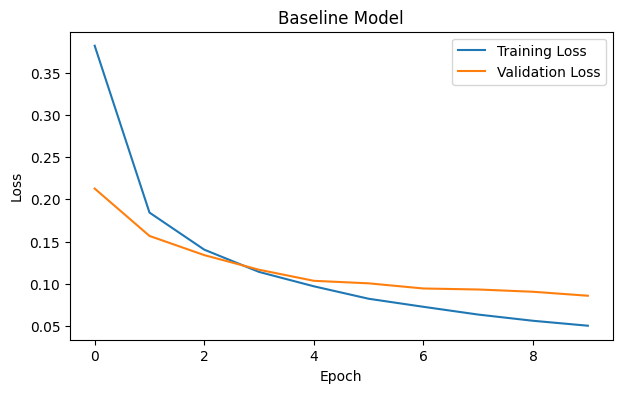

In [7]:
history_base = model_base.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

loss_base, acc_base = model_base.evaluate(X_test, y_test)
print("Test Loss: ", loss_base)
print("Test Accuracy: ", acc_base)

plot_loss(history_base, "Baseline Model")

model_base.save("mnist_baseline.keras")
model_load = keras.models.load_model("mnist_baseline.keras")

## L1 Regularization

In [8]:
model_l1 = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l1(0.00001)
    ),
    Dense(10, activation="softmax")
])

model_l1.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_l1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8922 - loss: 0.4067 - val_accuracy: 0.9385 - val_loss: 0.2386
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9442 - loss: 0.2137 - val_accuracy: 0.9532 - val_loss: 0.1833
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9572 - loss: 0.1689 - val_accuracy: 0.9615 - val_loss: 0.1556
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9653 - loss: 0.1411 - val_accuracy: 0.9652 - val_loss: 0.1375
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9708 - loss: 0.1228 - val_accuracy: 0.9687 - val_loss: 0.1228
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9746 - loss: 0.1100 - val_accuracy: 0.9711 - val_loss: 0.1199
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9778 - loss: 0.0994 - val_accuracy: 0.9725 - val_loss: 0.1153
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9796 - loss: 0.0927 - val_accuracy: 0.

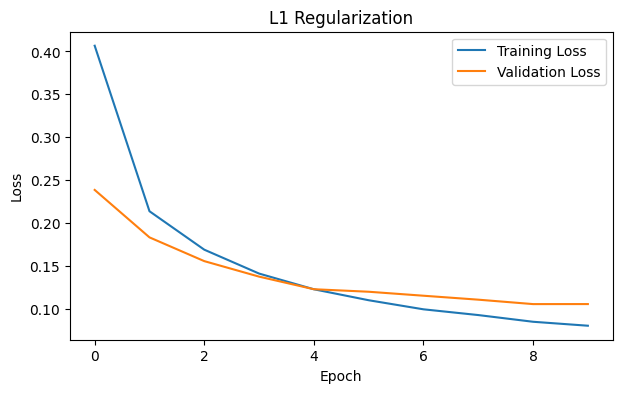

In [9]:
history_l1 = model_l1.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

loss_l1, acc_l1 = model_l1.evaluate(X_test, y_test)
print("L1 Test Loss: ", loss_l1)
print("L1 Test Accuracy: ", acc_l1)
plot_loss(history_l1, "L1 Regularization")

## L2 Regularization

In [10]:
model_l2 = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l2(0.0001)
    ),
    Dense(10, activation="softmax")
])

model_l2.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_l2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8935 - loss: 0.4002 - val_accuracy: 0.9356 - val_loss: 0.2344
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9446 - loss: 0.2104 - val_accuracy: 0.9526 - val_loss: 0.1834
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9572 - loss: 0.1666 - val_accuracy: 0.9609 - val_loss: 0.1550
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9659 - loss: 0.1398 - val_accuracy: 0.9643 - val_loss: 0.1405
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9715 - loss: 0.1227 - val_accuracy: 0.9658 - val_loss: 0.1316
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9746 - loss: 0.1108 - val_accuracy: 0.9681 - val_loss: 0.1269
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9777 - loss: 0.1019 - val_accuracy: 0.9720 - val_loss: 0.1174
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9797 - loss: 0.0950 - val_accuracy: 0.

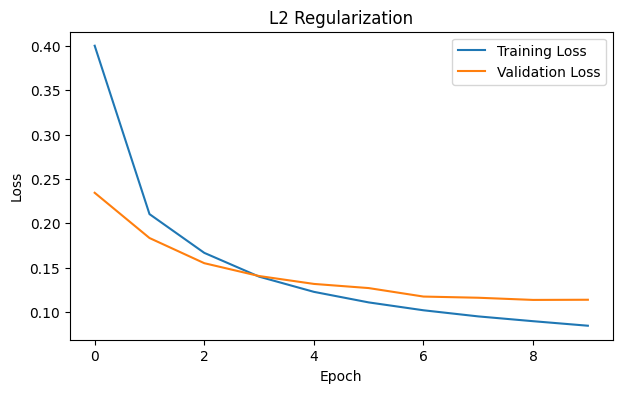

In [11]:
history_l2 = model_l2.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

loss_l2, acc_l2 = model_l2.evaluate(X_test, y_test)

print("L2 Test Loss: ", loss_l2)
print("L2 Test Accuracy: ", acc_l2)

plot_loss(history_l2, "L2 Regularization")

## Dropout

In [12]:
model_dropout = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model_dropout.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_dropout.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8490 - loss: 0.5179 - val_accuracy: 0.9307 - val_loss: 0.2450
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9197 - loss: 0.2792 - val_accuracy: 0.9478 - val_loss: 0.1818
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9341 - loss: 0.2267 - val_accuracy: 0.9543 - val_loss: 0.1537
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9418 - loss: 0.2005 - val_accuracy: 0.9605 - val_loss: 0.1361
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9464 - loss: 0.1798 - val_accuracy: 0.9625 - val_loss: 0.1252
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9501 - loss: 0.1675 - val_accuracy: 0.9658 - val_loss: 0.1154
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9535 - loss: 0.1541 - val_accuracy: 0.9660 - val_loss: 0.1120
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9553 - loss: 0.1475 - val_accuracy: 0.

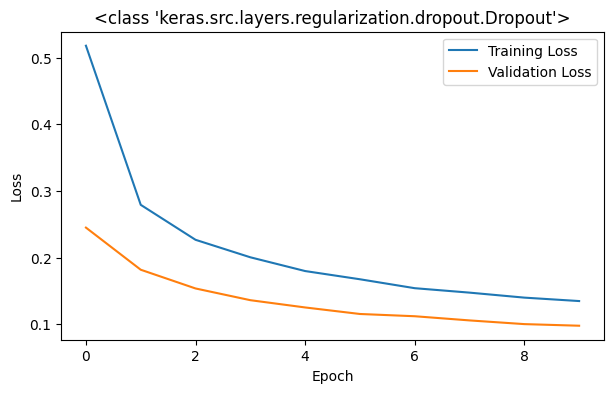

In [13]:
history_dropout = model_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

loss_dropout, acc_dropout = model_dropout.evaluate(X_test, y_test)

print("Dropout Test Loss: ", loss_dropout)
print("Dropout Test Accuracy: ", acc_dropout)

plot_loss(history_dropout, Dropout)

## Early Stopping

In [14]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_early = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

model_early.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_early.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8912 - loss: 0.3910 - val_accuracy: 0.9376 - val_loss: 0.2173
Epoch 2/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9451 - loss: 0.1930 - val_accuracy: 0.9543 - val_loss: 0.1618
Epoch 3/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9573 - loss: 0.1466 - val_accuracy: 0.9624 - val_loss: 0.1355
Epoch 4/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9653 - loss: 0.1204 - val_accuracy: 0.9658 - val_loss: 0.1183
Epoch 5/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9708 - loss: 0.1017 - val_accuracy: 0.9671 - val_loss: 0.1146
Epoch 6/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9741 - loss: 0.0874 - val_accuracy: 0.9679 - val_loss: 0.1077
Epoch 7/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9774 - loss: 0.0762 - val_accuracy: 0.9702 - val_loss: 0.0979
Epoch 8/30
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9804 - loss: 0.0670 - val_accuracy: 0.

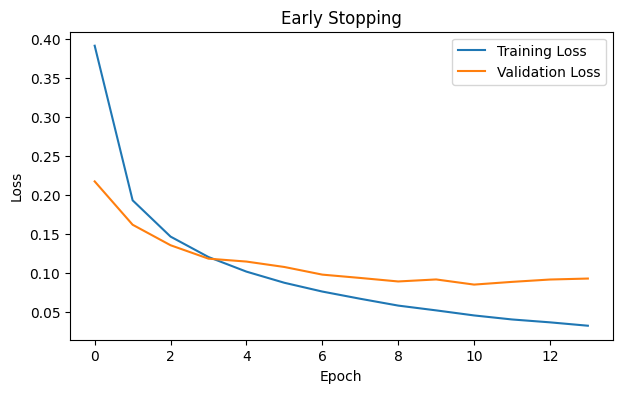

In [16]:
history_early = model_early.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=100,
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

loss_early, acc_early = model_early.evaluate(X_test, y_test)

print("Early Stopping Test Loss: ", loss_early)
print("Early Stopping Test Accuracy: ", acc_early)
print("Epoch yang dijalankan: ", len(history_early.history["loss"]))

plot_loss(history_early, "Early Stopping")

## L1 + Dropout

In [17]:
model_l1_dropout = Sequential([
    Input(shape=(28, 28, 1)),
    Flatten(),
    Dense(
        64,
        activation="relu",
        kernel_regularizer=l1(0.00001)
    ),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model_l1_dropout.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model_l1_dropout.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8547 - loss: 0.5201 - val_accuracy: 0.9355 - val_loss: 0.2497
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9226 - loss: 0.2873 - val_accuracy: 0.9492 - val_loss: 0.1911
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9353 - loss: 0.2394 - val_accuracy: 0.9575 - val_loss: 0.1639
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9433 - loss: 0.2131 - val_accuracy: 0.9638 - val_loss: 0.1465
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9475 - loss: 0.1976 - val_accuracy: 0.9651 - val_loss: 0.1401
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9520 - loss: 0.1855 - val_accuracy: 0.9683 - val_loss: 0.1311
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9546 - loss: 0.1742 - val_accuracy: 0.9693 - val_loss: 0.1267
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9573 - loss: 0.1662 - val_accuracy: 0.

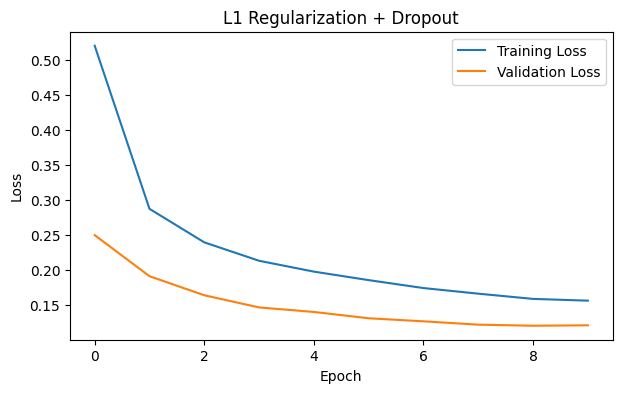

In [18]:
history_l1_dropout = model_l1_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

loss_l1_dropout, acc_l1_dropout = model_l1_dropout.evaluate(
    X_test,
    y_test
)

print("L1 + Dropout Test Loss: ", loss_l1_dropout)
print("L1 + Dropout Tess Accuracy: ", acc_l1_dropout)

plot_loss(history_l1_dropout, "L1 Regularization + Dropout")

## Perbandingan Semua Hasil


In [20]:
results = {
    "Model": [
        "Baseline",
        "L1",
        "L2",
        "Dropout",
        "Early Stopping",
        "L1 + Dropout"
    ],
    
    "Test Loss": [
        loss_base,
        loss_l1,
        loss_l2,
        loss_dropout,
        loss_early,
        loss_l1_dropout
    ],
    
    "Test Accuracy": [
        acc_base,
        acc_l1,
        acc_l2,
        acc_dropout,
        acc_early,
        acc_l1_dropout
    ]
}

import pandas as pd

df_results = pd.DataFrame(results)
df_results

,Model,Test Loss,Test Accuracy
0,Baseline,0.085812,0.9736
1,L1,0.105533,0.9746
2,L2,0.113788,0.9729
3,Dropout,0.097799,0.9711
4,Early Stopping,0.085117,0.9755
5,L1 + Dropout,0.120994,0.9714


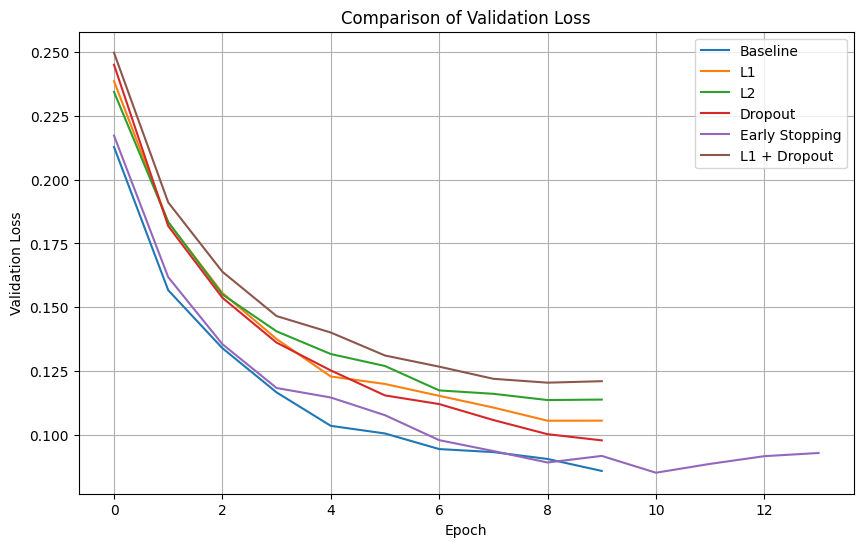

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(history_base.history['val_loss'], label='Baseline')
plt.plot(history_l1.history['val_loss'], label='L1')
plt.plot(history_l2.history['val_loss'], label='L2')
plt.plot(history_dropout.history['val_loss'], label='Dropout')
plt.plot(history_early.history['val_loss'], label='Early Stopping')
plt.plot(history_l1_dropout.history['val_loss'], label='L1 + Dropout')

plt.title('Comparison of Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

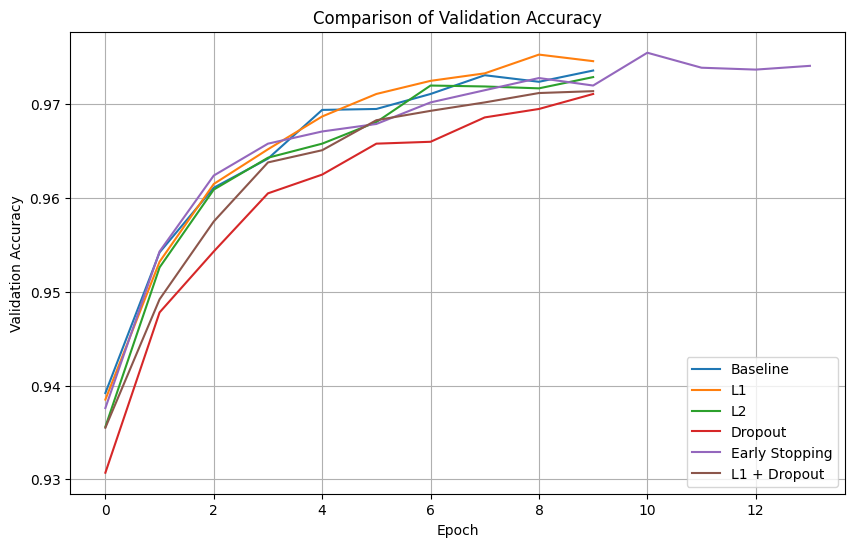

In [22]:
plt.figure(figsize=(10, 6))

plt.plot(history_base.history['val_accuracy'], label='Baseline')
plt.plot(history_l1.history['val_accuracy'], label='L1')
plt.plot(history_l2.history['val_accuracy'], label='L2')
plt.plot(history_dropout.history['val_accuracy'], label='Dropout')
plt.plot(history_early.history['val_accuracy'], label='Early Stopping')
plt.plot(history_l1_dropout.history['val_accuracy'], label='L1 + Dropout')

plt.title('Comparison of Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

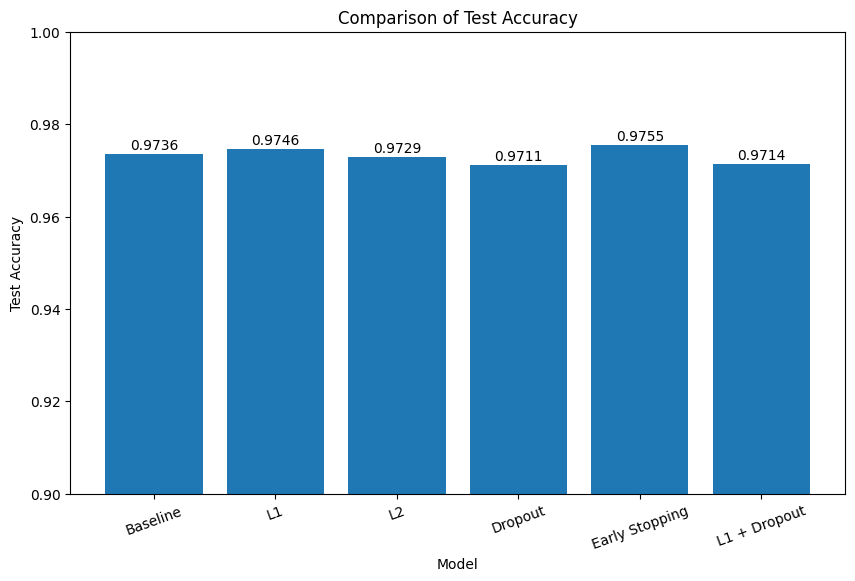

In [23]:
models = [
    'Baseline',
    'L1',
    'L2',
    'Dropout',
    'Early Stopping',
    'L1 + Dropout'
]

accuracies = [
    acc_base,
    acc_l1,
    acc_l2,
    acc_dropout,
    acc_early,
    acc_l1_dropout
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, accuracies)

plt.title('Comparison of Test Accuracy')
plt.xlabel('Model')
plt.ylabel('Test Accuracy')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=20)

# Menampilkan angka accuracy di atas bar
for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.001,
        f'{acc:.4f}',
        ha='center'
    )

plt.show()

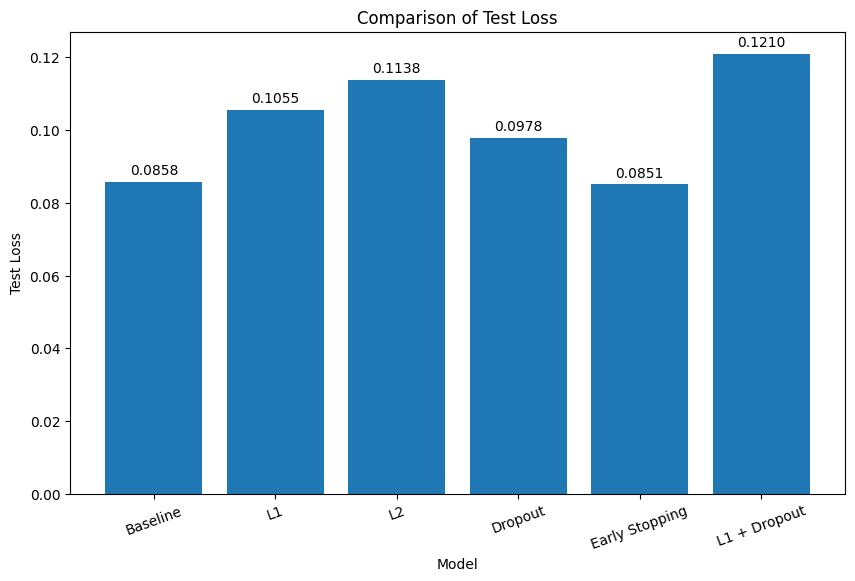

In [24]:
losses = [
    loss_base,
    loss_l1,
    loss_l2,
    loss_dropout,
    loss_early,
    loss_l1_dropout
]

plt.figure(figsize=(10, 6))

bars = plt.bar(models, losses)

plt.title('Comparison of Test Loss')
plt.xlabel('Model')
plt.ylabel('Test Loss')
plt.xticks(rotation=20)

# Menampilkan nilai loss di atas bar
for bar, loss in zip(bars, losses):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.002,
        f'{loss:.4f}',
        ha='center'
    )

plt.show()